# Loot Box Harcaması ve Günlük Oyun Süresi

Veri: Etchells, Morgan ve Quintana (2022) açık erişimli anket verisi (OSF: osf.io/2zhrm). Bu notebook, OSF'den indirilen orijinal veri dosyasını (`LootboxOSFdata.csv`) doğrudan okur ve loot box'a para harcayan ile harcamayan oyuncuların günlük oyun sürelerini karşılaştırır.

##  Veri tanıtımı

- **Veri setinin adı ve bağlantısı:** Etchells, Morgan ve Quintana (2022) loot box anketi verisi, `LootboxOSFdata.csv`. Bağlantı: https://osf.io/2zhrm (DOI: 10.17605/OSF.IO/2ZHRM).
- **Veri kaynağı / lisans / erişim tarihi:** Veri, makalenin yazarları tarafından Open Science Framework (OSF) üzerinde açık erişime sunulmuştur. Erişim tarihi:22.10.2026
- **CSV mi, JSON mu?:** CSV.
- **Satır ve sütunların anlamı:** Her satır ankete katılan bir oyuncuyu temsil eder. Sütunlar demografik bilgileri (cinsiyet, yaş, ülke), günlük oyun süresini, oynanan oyunu ve platformu, geliri, harcama türlerini (loot box, oyun içi diğer, diğer dijital, kumar) ve ölçek skorlarını (problemli kumar PGSI, aşırı oyun IGD, ruhsal iyi oluş WEMWBS, psikolojik sıkıntı Kessler) içerir.
- **Ölçü birimi ve gözlem sayısı:** Oyun süresi günlük saat, harcamalar ve gelirler aylık İngiliz sterlini (GBP) cinsindendir. Toplam 2.728 gözlem (katılımcı) vardır.
- **Gerçek mi / açık kaynak mı / temsili mi?:** Gerçek oyunculardan toplanmış gerçek anket verisidir ve açık erişimlidir.

In [ ]:
# 1) OSF'den indirdiğin orijinal veri dosyasını seç (LootboxOSFdata.csv)
from google.colab import files
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]
print("Yüklenen dosya:", dosya_adi)

Saving LootboxOSFdata.csv to LootboxOSFdata (3).csv
Yüklenen dosya: LootboxOSFdata (3).csv


In [ ]:
# 2) Dosyayı oku
import pandas as pd

# En son yüklenen CSV dosyasını okuyalım
df = pd.read_csv(dosya_adi)

# URN sütununu kaldır
if 'URN' in df.columns:
    df = df.drop(columns=['URN'])

print("Kalan sütunlar:", list(df.columns[:5]), "...")
df.head()

Kalan sütunlar: ['Gender', 'Age', 'Country of Residence', 'Time spent gaming per day (hours)', 'Platform'] ...


,Gender,Age,Country of Residence,Time spent gaming per day (hours),Platform,Game,Quali why buy lootboxes,Monthly Income,Disposable income,Lootbox spend,In-game non-LB spend,Other digital purchases,Gambling spend,Risky LB spending score,WEMWBS score,Kessler score,PGSI score,PGSI categorical,IGD
0,1,18,143,2.0,1,Counter Strike,It's quite fun but it has to be in control.,114.722753,19.120459,9.560229,0.000000,3.059273,38.240918,22,42,33,8.0,3,20
1,1,19,143,4.0,1,counter strike global offensive,Adrenaline,478.011472,114.722753,5.736138,19.120459,0.000000,0.000000,26,54,14,3.0,2,12
2,1,20,1,2.0,1,Counter Strike Global Offensive,"It's fun, like gambling there's a chance for a...",1500.000000,1000.000000,0.000000,125.000000,0.000000,5.000000,27,41,24,3.0,2,23
3,1,26,143,4.0,1,Counter-Strike: Global Offensive,"I buy loot boxes, because I want my gun skin l...",573.613767,95.602294,0.000000,9.560229,4.780115,3.059273,13,39,29,1.0,1,18
4,2,30,143,1.0,1,Star Wars Battlefront II,i want to have better experience while playing...,573.613767,363.288719,11.472275,0.000000,11.472275,47.801147,25,49,21,2.0,1,18


In [ ]:
# 3) Gerekli sütunlar ve gruplar
import matplotlib.pyplot as plt
import numpy as np

# Sütun isimlerindeki olası gizli boşlukları temizleyelim
df.columns = df.columns.str.strip()

sure = "Time spent gaming per day (hours)"   # günlük oyun süresi
harcama = "Lootbox spend"                    # aylık loot box harcaması (GBP)

df["grup"] = np.where(df[harcama] > 0, "Harcayan", "Harcamayan")
df["grup"].value_counts()

,count
grup,
Harcamayan,1641
Harcayan,1087


In [ ]:
# 4) Gruplara göre özet tablo
tablo = df.groupby("grup")[sure].agg(
    Kisi_sayisi="count",
    Ortalama="mean",
    Medyan="median",
    Q1=lambda s: s.quantile(0.25),
    Q3=lambda s: s.quantile(0.75),
).round(2)
tablo

,Kisi_sayisi,Ortalama,Medyan,Q1,Q3
grup,,,,,
Harcamayan,1641,2.06,1.5,1.0,2.5
Harcayan,1087,2.64,2.0,1.0,3.0


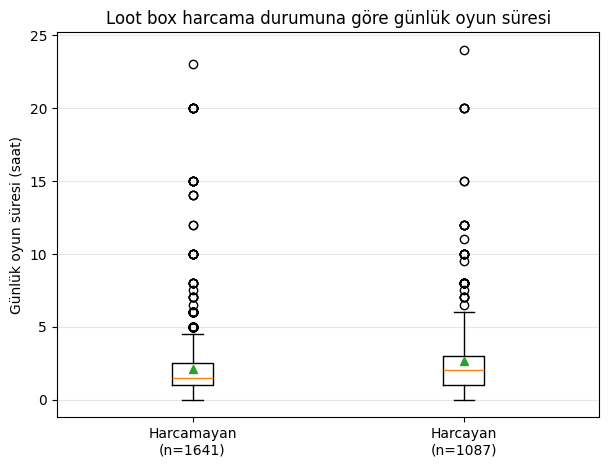

In [ ]:
# 5) Kutu grafiği
gruplar = ["Harcamayan", "Harcayan"]
veri = [df.loc[df["grup"] == g, sure] for g in gruplar]
etiketler = [f"{g}\n(n={len(v)})" for g, v in zip(gruplar, veri)]

fig, ax = plt.subplots(figsize=(7, 5))
ax.boxplot(veri, showmeans=True)
ax.set_xticks([1, 2])
ax.set_xticklabels(etiketler)
ax.set_ylabel("Günlük oyun süresi (saat)")
ax.set_title("Loot box harcama durumuna göre günlük oyun süresi")
ax.grid(axis="y", alpha=0.3)

plt.savefig("oyun_suresi_kutu_grafigi.png", dpi=200, bbox_inches="tight")
plt.show()



**Veri kaynağı ve değişken:** Grafik, Etchells, Morgan ve Quintana (2022) anket verisine dayanır. Karşılaştırılan değişken, katılımcıların bildirdiği günlük oyun süresidir (`Time spent gaming per day (hours)`). Katılımcılar, `Lootbox spend` değeri 0'dan büyükse "Harcayan", 0 ise "Harcamayan" olarak iki gruba ayrılmıştır.

**Toplam / ortalama ve birimler:** Toplam 2.728 katılımcı vardır: 1.641 harcamayan ve 1.087 harcayan. Günlük oyun süresi saat cinsindendir. Harcamayan grubun ortalaması 2,06 saat, medyanı 1,5 saattir. Harcayan grubun ortalaması 2,64 saat, medyanı 2 saattir. Çeyreklik değerlere göre harcamayanlarda orta %50'lik kesim 1 ile 2,5 saat, harcayanlarda 1 ile 3 saat arasındadır.

**Grafikte görülen bulgu:** Harcayan grubun medyan çizgisi ve kutusunun üst sınırı harcamayan gruba göre biraz daha yukarıdadır. Yani harcayan oyuncular ortalamada günde yaklaşık yarım saat daha fazla oynadıklarını bildirmiştir. Fark küçüktür ve iki grubun kutuları büyük ölçüde örtüşür. Her iki grupta da 20 saati aşan uç değerler vardır ve dağılım sağa çarpıktır, bu yüzden ortalama yerine medyana bakmak daha güvenlidir. Bu bulgu, harcayanların daha uzun oynama eğiliminde olduğuna işaret eder ama bu notebook'ta fark için bir istatistiksel anlamlılık testi yapılmamıştır.

**Sınırlılıklar ve ölçemediği şeyler:** Veri kesitsel olduğu için grafik, loot box harcamasının oyun süresini artırdığını göstermez, yalnızca iki değişkenin ilişkili olabileceğini gösterir. Her iki değişken de katılımcıların kendi bildirimine dayanır ve hatalı olabilir. Örneklem gönüllülerden oluştuğu ve pandemi döneminde toplandığı için sonuçlar tüm oyunculara genellenemez. Yaş, gelir ve aşırı oyun skoru gibi etkenler kontrol edilmemiştir, uç değerler (örneğin 12 saat ve üzeri) veriden çıkarılmamıştır. Grafik, harcamanın miktarını, hangi oyunda harcandığını ve oyuncunun neden harcadığını da ölçmez.